<a href="https://colab.research.google.com/github/bhureau/pytorch_learning/blob/main/extras/exercises/03_pytorch_computer_vision_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03. PyTorch Computer Vision Exercises

The following is a collection of exercises based on computer vision fundamentals in PyTorch.

They're a bunch of fun.

You're going to get to write plenty of code!

## Resources

1. These exercises are based on [notebook 03 of the Learn PyTorch for Deep Learning course](https://www.learnpytorch.io/03_pytorch_computer_vision/).
2. See a live [walkthrough of the solutions (errors and all) on YouTube](https://youtu.be/_PibmqpEyhA).
  * **Note:** Going through these exercises took me just over 3 hours of solid coding, so you should expect around the same.
3. See [other solutions on the course GitHub](https://github.com/mrdbourke/pytorch-deep-learning/tree/main/extras/solutions).

In [1]:
# Check for GPU
!nvidia-smi

Fri Nov 20 14:12:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
# Import torch
import torch

# Exercises require PyTorch > 1.10.0
print(torch.__version__)

# TODO: Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device


2.14.1+cu130


'cuda'

## 1. What are 3 areas in industry where computer vision is currently being used?

In [ ]:
Automotive, Healthcare, agroalimentaire

## 2. Search "what is overfitting in machine learning" and write down a sentence about what you find.

In [ ]:
Overfitting is when a model contains too many parameters and therefore will fit the training data too well but will not generalize well to new data.

## 3. Search "ways to prevent overfitting in machine learning", write down 3 of the things you find and a sentence about each.
> **Note:** there are lots of these, so don't worry too much about all of them, just pick 3 and start with those.

In [ ]:
K means, cross validation, data augmentation, feature analysis

## 4. Spend 20-minutes reading and clicking through the [CNN Explainer website](https://poloclub.github.io/cnn-explainer/).

* Upload your own example image using the "upload" button on the website and see what happens in each layer of a CNN as your image passes through it.

## 5. Load the [`torchvision.datasets.MNIST()`](https://pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html#torchvision.datasets.MNIST) train and test datasets.

In [6]:
# Import PyTorch
import torch
from torch import nn

# Import torchvision
import torchvision
from torchvision import datasets
from torchvision.transforms import ToTensor

# Import matplotlib for visualization
import matplotlib.pyplot as plt

# Check versions
# Note: your PyTorch version shouldn't be lower than 1.10.0 and torchvision version shouldn't be lower than 0.11
print(f"PyTorch version: {torch.__version__}\ntorchvision version: {torchvision.__version__}")

# Setup training data
train_data = datasets.FashionMNIST(
    root="data", # where to download data to?
    train=True, # get training data
    download=True, # download data if it doesn't exist on disk
    transform=ToTensor(), # images come as PIL format, we want to turn into Torch tensors
    target_transform=None # you can transform labels as well
)

# Setup testing data
test_data = datasets.FashionMNIST(
    root="data",
    train=False, # get test data
    download=True,
    transform=ToTensor()
)

PyTorch version: 2.14.1+cu130
torchvision version: 0.29.1+cu130


100%|██████████| 26.4M/26.4M [00:01<00:00, 13.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 201kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.74MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.8MB/s]


## 6. Visualize at least 5 different samples of the MNIST training dataset.

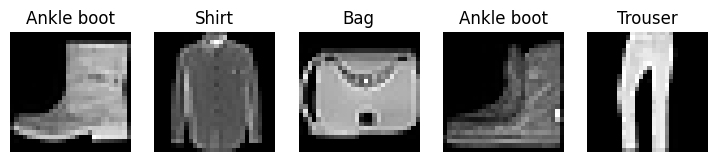

In [14]:
class_names = train_data.classes
torch.manual_seed(42)
fig = plt.figure(figsize=(9, 9))
rows, cols = 1, 5
for i in range(1, rows * cols + 1):
    random_idx = torch.randint(0, len(train_data), size=[1]).item()
    img, label = train_data[random_idx]
    fig.add_subplot(rows, cols, i)
    plt.imshow(img.squeeze(), cmap="gray")
    plt.title(class_names[label])
    plt.axis(False);

## 7. Turn the MNIST train and test datasets into dataloaders using `torch.utils.data.DataLoader`, set the `batch_size=32`.

In [16]:
BATCH_SIZE = 32
train_dataloader=torch.utils.data.DataLoader(train_data,batch_size=BATCH_SIZE,shuffle=True)
test_dataloader=torch.utils.data.DataLoader(test_data,batch_size=BATCH_SIZE,shuffle=False)

## 8. Recreate `model_2` used in notebook 03 (the same model from the [CNN Explainer website](https://poloclub.github.io/cnn-explainer/), also known as TinyVGG) capable of fitting on the MNIST dataset.

In [37]:
class TinyVGG(nn.Module):
    """Creates the TinyVGG architecture"""
    def __init__(self, in_features, out_features, hidden_unit):
        super().__init__()
        self.layer_stack=nn.Sequential(
            nn.Conv2d(in_features,hidden_unit,3,padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_unit,hidden_unit,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(hidden_unit,hidden_unit,3,padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_unit,hidden_unit,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            # Where did this in_features shape come from?
            # It's because each layer of our network compresses and changes the shape of our input data.
            nn.Linear(in_features=hidden_unit*7*7,
                      out_features=out_features)
        )

    def forward(self,x):
      return self.classifier(self.layer_stack(x))

## 9. Train the model you built in exercise 8. for 5 epochs on CPU and GPU and see how long it takes on each.

In [38]:
torch.manual_seed(42)
model_2=TinyVGG(in_features=1,out_features=10,hidden_unit=10).to(device)
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.SGD(model_2.parameters(),lr=0.1)

epochs = 5
for epoch in range(epochs):
  model_2.train()
  for batch, (X,y) in enumerate(train_dataloader):
    X,y=X.to(device),y.to(device)
    y_pred=model_2(X)
    loss=loss_fn(y_pred,y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

  model_2.eval()
  with torch.inference_mode():
    test_loss,test_acc=0,0
    for X,y in test_dataloader:
      X,y=X.to(device),y.to(device)
      test_pred=model_2(X)
      test_loss+=loss_fn(test_pred,y)
      test_acc+=(test_pred.argmax(dim=1)==y).sum().item()/len(test_pred)

      print(f"Epoch: {epoch+1} | Train loss: {loss:.4f} | Test loss: {test_loss/len(test_dataloader)} | Test acc: {test_acc/len(test_dataloader)}")

Epoch: 1 | Train loss: 0.3106 | Test loss: 0.0014925682917237282 | Test acc: 0.0026956869009584663
Epoch: 1 | Train loss: 0.3106 | Test loss: 0.0027642063796520233 | Test acc: 0.005191693290734824
Epoch: 1 | Train loss: 0.3106 | Test loss: 0.003708264324814081 | Test acc: 0.008087060702875399
Epoch: 1 | Train loss: 0.3106 | Test loss: 0.004379228688776493 | Test acc: 0.010982428115015975
Epoch: 1 | Train loss: 0.3106 | Test loss: 0.005672622937709093 | Test acc: 0.01387779552715655
Epoch: 1 | Train loss: 0.3106 | Test loss: 0.006490807980298996 | Test acc: 0.016673322683706072
Epoch: 1 | Train loss: 0.3106 | Test loss: 0.007079260889440775 | Test acc: 0.019768370607028754
Epoch: 1 | Train loss: 0.3106 | Test loss: 0.00882906187325716 | Test acc: 0.022364217252396165
Epoch: 1 | Train loss: 0.3106 | Test loss: 0.009651459753513336 | Test acc: 0.02525958466453674
Epoch: 1 | Train loss: 0.3106 | Test loss: 0.011031251400709152 | Test acc: 0.027855431309904154
Epoch: 1 | Train loss: 0.3106 

## 10. Make predictions using your trained model and visualize at least 5 of them comparing the prediciton to the target label.

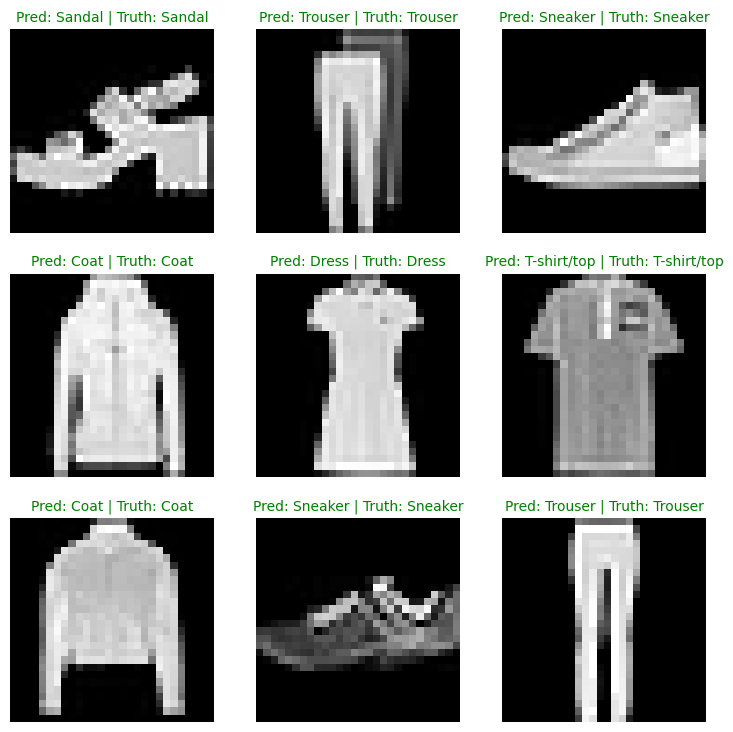

In [42]:
def make_predictions(model: torch.nn.Module, data: list, device: torch.device = device):
    pred_probs = []
    model.eval()
    with torch.inference_mode():
        for sample in data:
            # Prepare sample
            sample = torch.unsqueeze(sample, dim=0).to(device) # Add an extra dimension and send sample to device

            # Forward pass (model outputs raw logit)
            pred_logit = model(sample)

            # Get prediction probability (logit -> prediction probability)
            pred_prob = torch.softmax(pred_logit.squeeze(), dim=0) # note: perform softmax on the "logits" dimension, not "batch" dimension (in this case we have a batch size of 1, so can perform on dim=0)

            # Get pred_prob off GPU for further calculations
            pred_probs.append(pred_prob.cpu())

    # Stack the pred_probs to turn list into a tensor
    return torch.stack(pred_probs)

import random
random.seed(42)
test_samples = []
test_labels = []
for sample, label in random.sample(list(test_data), k=9):
    test_samples.append(sample)
    test_labels.append(label)

pred_probs= make_predictions(model=model_2,
                             data=test_samples)
pred_classes = pred_probs.argmax(dim=1)

plt.figure(figsize=(9, 9))
nrows = 3
ncols = 3
for i, sample in enumerate(test_samples):
  # Create a subplot
  plt.subplot(nrows, ncols, i+1)

  # Plot the target image
  plt.imshow(sample.squeeze(), cmap="gray")

  # Find the prediction label (in text form, e.g. "Sandal")
  pred_label = class_names[pred_classes[i]]

  # Get the truth label (in text form, e.g. "T-shirt")
  truth_label = class_names[test_labels[i]]

  # Create the title text of the plot
  title_text = f"Pred: {pred_label} | Truth: {truth_label}"

  # Check for equality and change title colour accordingly
  if pred_label == truth_label:
      plt.title(title_text, fontsize=10, c="g") # green text if correct
  else:
      plt.title(title_text, fontsize=10, c="r") # red text if wrong
  plt.axis(False);

## 11. Plot a confusion matrix comparing your model's predictions to the truth labels.

Making predictions:   0%|          | 0/313 [00:00<?, ?it/s]

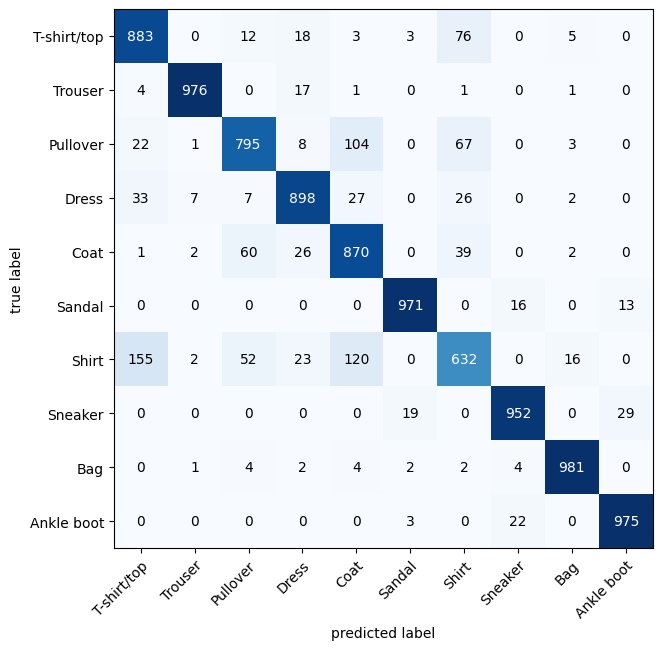

In [47]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix
from tqdm.auto import tqdm

# 1. Make predictions with trained model
y_preds = []
model_2.eval()
with torch.inference_mode():
  for X, y in tqdm(test_dataloader, desc="Making predictions"):
    # Send data and targets to target device
    X, y = X.to(device), y.to(device)
    # Do the forward pass
    y_logit = model_2(X)
    # Turn predictions from logits -> prediction probabilities -> predictions labels
    y_pred = torch.softmax(y_logit, dim=1).argmax(dim=1) # note: perform softmax on the "logits" dimension, not "batch" dimension (in this case we have a batch size of 32, so can perform on dim=1)
    # Put predictions on CPU for evaluation
    y_preds.append(y_pred.cpu())
# Concatenate list of predictions into a tensor
y_pred_tensor = torch.cat(y_preds)
# 2. Setup confusion matrix instance and compare predictions to targets
confmat = ConfusionMatrix(num_classes=len(class_names), task='multiclass')
confmat_tensor = confmat(preds=y_pred_tensor,
                         target=test_data.targets)

# 3. Plot the confusion matrix
fig, ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(), # matplotlib likes working with NumPy
    class_names=class_names, # turn the row and column labels into class names
    figsize=(10, 7));

## 12. Create a random tensor of shape `[1, 3, 64, 64]` and pass it through a `nn.Conv2d()` layer with various hyperparameter settings (these can be any settings you choose), what do you notice if the `kernel_size` parameter goes up and down?

In [53]:
random_tensor = torch.randn(size=(1, 3, 64,64))
max_pool_layer = nn.Conv2d(3,10,kernel_size=2,padding=1)
max_pool_layer(random_tensor).shape


torch.Size([1, 10, 63, 63])

## 13. Use a model similar to the trained `model_2` from notebook 03 to make predictions on the test [`torchvision.datasets.FashionMNIST`](https://pytorch.org/vision/main/generated/torchvision.datasets.FashionMNIST.html) dataset.
* Then plot some predictions where the model was wrong alongside what the label of the image should've been.
* After visualing these predictions do you think it's more of a modelling error or a data error?
* As in, could the model do better or are the labels of the data too close to each other (e.g. a "Shirt" label is too close to "T-shirt/top")?